# 3.7 — Distillation maître-élève : transférer le savoir, pas les poids

**Navigation** : [<< 3.6-Modèles génératifs](3.6-Modeles-Generatifs.ipynb) · [Feuille de route de la série](README.md) · [3.8 — Représentations contrastives >>](3.8-Representations-Contrastives.ipynb)

Voisins de la famille compression : [3.9 — Compression et quantification](3.9-Compression-Quantization-FP.ipynb) · [3.9b — Pruning from scratch](3.9b-Compression-Pruning-from-scratch.ipynb) · [3.9e — Quantification SOTA](3.9e-Compression-SOTA.ipynb) · [3.9g — Comparatif A vs B](3.9g-Compression-Comparatif-A-vs-B.ipynb)

La série compresse un même réseau par plusieurs axes. [3.9](3.9-Compression-Quantization-FP.ipynb) comprime les **nombres** (INT8 au lieu de FP32) ; les carnets de pruning de la même famille compriment les **connexions**. Ce carnet comprime le **modèle lui-même** : entraîner un petit réseau — l'élève ResNet-8, ~3,5× moins de poids — à **imiter la sortie d'un grand réseau** — le maître ResNet-20 — plutôt qu'à apprendre seul. C'est la *knowledge distillation* de Hinton, Vinyals & Dean (2015).

Le fil est celui de la série : **le mécanisme d'abord** — la loss de distillation écrite à la main, le facteur `T²` vérifié numériquement, les *hints* de FitNets — puis la mesure (exactitude sur plusieurs graines, calibration, taille, latence), puis un verdict explicite en unités de σ.

Ce carnet est le point de convergence de la distillation dans la série : il porte le terrain canonique de la compression (ResNet sur CIFAR-10, entraînés pour de vrai ici) et absorbe l'ancien carnet « distillation from scratch » de la famille 3.9, pour que la KD soit enseignée une seule fois, au bon endroit.

Kernel : `coursia-ml-training` (torch + torchvision + matplotlib).

## Le contrat de ce carnet

Quatre questions, chacune tranchée par une mesure :

1. **La loss complète aide-t-elle à budget égal ?** CE dure + `T²·KL` molle, mêmes époques, même recette d'optimisation — l'élève ResNet-8 gagne-t-il quelque chose à imiter le maître ResNet-20 plutôt qu'à apprendre seul ?
2. **Le facteur `T²` fait-il ce qu'on dit ?** La littérature l'affirme ; on le vérifie sur le gradient, puis on mesure ce que la température fait au gain.
3. **Au-delà des logits : les *hints* de FitNets ajoutent-ils par-dessus ?** On distille aussi la carte de caractéristiques de l'étage 2.
4. **Que coûte et que compresse exactement la distillation ?** Temps d'entraînement (il faut d'abord le maître), poids gagnés, latence, exactitude et **calibration** rendues.

Le protocole reste celui de la série : 3 graines par configuration, écarts-types propagés, verdict en unités de σ — pas de « ça a l'air mieux ».

In [1]:
import os
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 40 if DEV == "cuda" else 6    # recette complete sur GPU, reduite sur CPU
SEEDS = [0, 1, 2] if DEV == "cuda" else [0]
T_DEFAULT, ALPHA = 4.0, 0.7
print(f"device={DEV}  torch={torch.__version__}  epochs={EPOCHS}  seeds={SEEDS}")

device=cuda  torch=2.14.1+cu126  epochs=40  seeds=[0, 1, 2]


## 1. La loss de distillation — deux cibles, une seule loss

Le maître répond à chaque image par un vecteur de logits $z_t$, l'élève par $z_s$. La loss de Hinton et al. mélange deux signaux :

$$\mathcal{L} = (1-\alpha)\,\mathrm{CE}(z_s, y) \;+\; \alpha\, T^2\, \mathrm{KL}\!\left(\mathrm{softmax}(z_t/T)\,\|\,\mathrm{softmax}(z_s/T)\right)$$

- la **CE dure** contre l'étiquette $y$ : l'élève apprend la tâche, comme toujours ;
- la **KL molle** contre le maître **tempéré** par $T$ : l'élève imite la *distribution* du maître, pas seulement son argmax.

Deux détails font toute la mécanique. La **température** $T$ aplatit les softmax : à $T=1$ le maître est quasi one-hot (son savoir ordinal est invisible), à $T$ élevé la hiérarchie des classes concurrentes émerge — c'est la *dark knowledge* que ce carnet exploite. Le **facteur $T^2$** compense l'aplatissement : la KL brute décroît en $\sim 1/T^2$ et, sans re-pondération, la partie molle s'évanouirait dès que $T$ monte — on le vérifie numériquement juste après, sur le gradient de la KL.

Le poids $\alpha$ arbitre entre les deux signaux ; on le fixe à 0,7 — le maître domine, l'étiquette garde la parole sur les cas où le maître se trompe.

In [2]:
def distill_loss(logits_s, logits_t, y, alpha=ALPHA, T=T_DEFAULT):
    """CE dure + KL molle (T^2) — la loss de Hinton et al. 2015, ecrite a la main."""
    ce = F.cross_entropy(logits_s, y)
    p_t = F.softmax(logits_t / T, dim=1)
    log_p_s = F.log_softmax(logits_s / T, dim=1)
    kl = F.kl_div(log_p_s, p_t, reduction="batchmean") * (T * T)
    return (1 - alpha) * ce + alpha * kl, ce.detach(), kl.detach()


# La dark knowledge sur un logit de maître plausible (classe vraie : 4).
z_t = torch.tensor([[0.2, -1.1, 0.4, -0.3, 4.2, -0.8, 0.1, -0.5, 0.9, 3.1]])
for T in (1.0, 4.0):
    p = F.softmax(z_t / T, dim=1)[0]
    print(f"T={T:.0f} : classe 4 -> {p[4]:.3f}   classe 9 -> {p[9]:.3f}   "
          f"les 8 autres -> {(1 - p[4] - p[9]).item():.3f} au total")

T=1 : classe 4 -> 0.685   classe 9 -> 0.228   les 8 autres -> 0.086 au total
T=4 : classe 4 -> 0.222   classe 9 -> 0.169   les 8 autres -> 0.609 au total


**Lecture.** À T = 1, le maître met 0,685 sur la classe 4 et 0,228 sur la classe 9 — la hiérarchie est là mais écrasée : les huit autres classes se partagent 0,086. À T = 4, l'écart se resserre (0,222 contre 0,169) et les huit autres classes se partagent 0,609 : la classe 9 devient une concurrente *documentée*, pas une égalité — l'ordre subsiste, l'amplitude s'efface. Cette structure ordinale — *qui ressemble à quoi* — ne coûte rien à collecter, ne figure dans aucune étiquette dure, et pourtant elle généralise : c'est elle que la KL transfère.

### Le facteur `T²` — vérifié, pas récité

Pourquoi multiplier la KL par `T²` ? La divergence de KL entre deux softmax tempérées a un gradient par rapport aux logits de l'élève qui **diminue comme `1/T²`** quand `T` grandit. Sans la compensation, à grande température le terme mou pèse quasi rien : la distillation s'éteint toute seule, et l'élève est piloté par le seul terme dur.

On le vérifie : on fixe des logits aléatoires et on mesure la norme du gradient de la KL **brute** puis de la KL **scalée par `T²`**, pour `T ∈ {1, 2, 5}`. On attend une KL brute qui chute ~`1/T²`, et une KL scalée qui reste constante (invariance d'échelle).

In [3]:
def grad_norm(T, scaled):
    torch.manual_seed(0)
    ls = torch.randn(64, 10, requires_grad=True)
    lt = torch.randn(64, 10)
    kl = F.kl_div(F.log_softmax(ls / T, 1), F.softmax(lt / T, 1), reduction="batchmean")
    if scaled:
        kl = kl * (T * T)
    g, = torch.autograd.grad(kl, ls)
    return g.norm().item()

print(f"{'T':>4} {'KL brute':>10} {'T^2*KL':>10}   {'facteur':>8}")
for T in [1.0, 2.0, 5.0]:
    nb = grad_norm(T, False); sc = grad_norm(T, True)
    print(f"{T:>4.1f} {nb:>10.4f} {sc:>10.4f}   {sc / nb:>8.2f}")

   T   KL brute     T^2*KL    facteur
 1.0     0.0591     0.0591       1.00
 2.0     0.0143     0.0573       4.00
 5.0     0.0022     0.0549      25.00


**Lecture** — la chute suit la loi d'échelle, l'invariance tient.

La colonne « KL brute » n'est **pas** la KL : c'est la **norme du gradient** de la KL. Sa chute suit
la loi d'échelle attendue — en divisant la température par 2 puis par 5, elle est multipliée par
4,1 puis par 26,9, soit $\approx 1/T^2$ (0,0591 → 0,0143 → 0,0022) — tandis que la colonne
$T^2 \cdot$ KL reste constante (0,0549 à 0,0591). C'est l'invariance d'échelle que l'énoncé
annonce : la température redimensionne la pente sans changer la divergence.

Concrètement, une température plus basse **augmente** la pente (le modèle suit les données plus
serré) sans rendre la divergence plus grande : c'est pourquoi le facteur $T^2$ est appliqué au
gradient dans le code ci-dessus.

## 2. Le terrain : un maître ResNet-20, un élève ResNet-8 — même famille, même recette

Les deux réseaux viennent d'une **famille paramétrée par la profondeur** : les largeurs d'étages (16, 32, 64 canaux) et le stem sont identiques, seules changent les profondeurs — trois blocs par étage pour le maître (ResNet-20), un seul pour l'élève (ResNet-8). Ce choix a un double intérêt : la comparaison est propre (même architecture générale, seul le volume de poids change), et la **carte de caractéristiques de l'étage 2 a exactement la même forme** (32 canaux, 16×16) chez le maître et chez l'élève — c'est ce qui permettra de brancher le *hint* FitNets de la section 5 sans adaptateur. Dans le cas général (largeurs différentes), une convolution 1×1 réconcilie les formes — c'est l'adaptateur de l'article original.

Le maître vise la barre de la série (~0,90 sur CIFAR-10 avec la recette SGD + momentum + cosine + augmentation — cf. [3.9](3.9-Compression-Quantization-FP.ipynb)) : distiller un maître médiocre fausserait la mesure, exactement comme un témoin affaibli faussait la mesure INT8.


In [4]:
DATA = os.path.join(os.path.expanduser("~"), ".cache", "coursia-datasets")
norm = transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
tfm = transforms.Compose([transforms.ToTensor(), norm])
tfm_train = transforms.Compose([transforms.RandomCrop(32, padding=4),
                                transforms.RandomHorizontalFlip(),
                                transforms.ToTensor(), norm])
train_set = datasets.CIFAR10(DATA, train=True, download=True, transform=tfm_train)
test_set = datasets.CIFAR10(DATA, train=False, download=True, transform=tfm)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=256, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=512, shuffle=False)
print(f"CIFAR-10 : {len(train_set)} train / {len(test_set)} test")

CIFAR-10 : 50000 train / 10000 test


In [5]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.short = None
        if stride != 1 or cin != cout:
            self.short = nn.Sequential(
                nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        y = F.relu(self.bn1(self.conv1(x)))
        y = self.bn2(self.conv2(y))
        y = y + (self.short(x) if self.short is not None else x)
        return F.relu(y)


class ResNetCifar(nn.Module):
    """ResNet CIFAR parametre par la profondeur : (3,3,3) = ResNet-20, (1,1,1) = ResNet-8.

    forward_with_hint renvoie (logits, carte s2) : la sortie de l'etage 2
    (32 canaux, 16x16) sert d'ancre FitNets. Les largeurs d'etage etant
    identiques entre profondeurs, maitre et eleve y produisent des tenseurs
    de meme forme — pas d'adaptateur 1x1 necessaire ici.
    """

    def __init__(self, blocks=(3, 3, 3), nclass=10):
        super().__init__()
        self.stem = nn.Conv2d(3, 16, 3, padding=1, bias=False)
        self.bn0 = nn.BatchNorm2d(16)
        self.s1 = self._stage(16, 16, blocks[0], 1)
        self.s2 = self._stage(16, 32, blocks[1], 2)
        self.s3 = self._stage(32, 64, blocks[2], 2)
        self.fc = nn.Linear(64, nclass)

    @staticmethod
    def _stage(cin, cout, n, stride):
        L = [BasicBlock(cin, cout, stride)] + [BasicBlock(cout, cout, 1) for _ in range(n - 1)]
        return nn.Sequential(*L)

    def _stem_s1_s2(self, x):
        x = F.relu(self.bn0(self.stem(x)))
        return self.s2(self.s1(x))

    def forward(self, x):
        x = self._stem_s1_s2(x)
        return self.fc(F.adaptive_avg_pool2d(self.s3(x), 1).flatten(1))

    def forward_with_hint(self, x):
        h = self._stem_s1_s2(x)
        logits = self.fc(F.adaptive_avg_pool2d(self.s3(h), 1).flatten(1))
        return logits, h


teacher = ResNetCifar((3, 3, 3)).to(DEV)
n_t = sum(p.numel() for p in teacher.parameters())
n_s = sum(p.numel() for p in ResNetCifar((1, 1, 1)).parameters())
print(f"ResNet-20 (maitre) : {n_t:,} parametres")
print(f"ResNet-8  (eleve)  : {n_s:,} parametres  (ratio {n_t / n_s:.1f}x)")

ResNet-20 (maitre) : 272,474 parametres
ResNet-8  (eleve)  : 78,042 parametres  (ratio 3.5x)


La recette d'entraînement est **la même pour tout le monde** — maître, élève témoin, élèves distillés : SGD (lr 0,08, momentum 0,9, weight decay 5·10⁻⁴), décroissance cosmique du pas, crops et flips aléatoires, autant d'époques. La seule différence entre le témoin de la section 3 et l'élève distillé de la section 4 est **la loss** : à budget strictement égal, toute différence d'exactitude est attribuable à la distillation, pas à un entraînement mieux réglé.

In [6]:
def evaluate(m, loader):
    m.eval()
    good = tot = 0
    with torch.no_grad():
        for x, y in loader:
            good += (m(x.to(DEV)).argmax(1).cpu() == y).sum().item()
            tot += y.numel()
    return good / tot


def run_student(kind, seed, T=T_DEFAULT, alpha=ALPHA, beta=0.0, epochs=EPOCHS,
                loader=None, hint_fn=None, tchr=None):
    """Entraîne un ResNet-8 ; kind in {scratch, kd, kd_hint}.

    scratch : CE seule (le temoin).  kd : CE + T^2 KL contre le maitre gele.
    kd_hint : kd + hint FitNets — erreur quadratique RELATIVE entre cartes s2
    (normalisee par l'energie du maitre, pour un beta comparable d'un run a
    l'autre ; hint_fn permet d'en substituer une autre — exercice 3).
    tchr permet de distiller depuis un autre maitre que le ResNet-20 de
    reference (exercice 5, ou l'on construit un mauvais maitre).
    Renvoie (exactitude finale, historique par epoque, secondes, modele).
    """
    torch.manual_seed(seed)
    ld = loader or train_loader
    m = ResNetCifar((1, 1, 1)).to(DEV)
    opt = torch.optim.SGD(m.parameters(), lr=0.08, momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    tch = teacher if tchr is None else tchr
    tch.eval()
    hist, t0 = [], time.perf_counter()
    for ep in range(epochs):
        m.train()
        for x, y in ld:
            x, y = x.to(DEV), y.to(DEV)
            logits, hint = m.forward_with_hint(x)
            if kind == "scratch":
                loss = F.cross_entropy(logits, y)
            else:
                with torch.no_grad():
                    t_logits, t_hint = tch.forward_with_hint(x)
                loss, _, _ = distill_loss(logits, t_logits, y, alpha, T)
                if beta:
                    if hint_fn is not None:
                        loss = loss + beta * hint_fn(hint, t_hint)
                    else:
                        rel = F.mse_loss(hint, t_hint) / t_hint.pow(2).mean().clamp_min(1e-8)
                        loss = loss + beta * rel
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        hist.append(evaluate(m, test_loader))
    return hist[-1], hist, time.perf_counter() - t0, m

In [7]:
opt = torch.optim.SGD(teacher.parameters(), lr=0.08, momentum=0.9, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
for ep in range(EPOCHS):
    teacher.train()
    t0 = time.perf_counter()
    for x, y in train_loader:
        loss = F.cross_entropy(teacher(x.to(DEV)), y.to(DEV))
        opt.zero_grad(); loss.backward(); opt.step()
    sched.step()
    if ep == 0 or (ep + 1) % 10 == 0:
        print(f"  ep {ep+1:2d}/{EPOCHS}  loss={loss.item():.4f}  ({time.perf_counter()-t0:.1f}s)")
acc_teacher = evaluate(teacher, test_loader)
print(f"[maitre ResNet-20] exactitude test = {acc_teacher:.4f}")

  ep  1/40  loss=1.4567  (15.2s)


  ep 10/40  loss=0.6559  (16.1s)


  ep 20/40  loss=0.4040  (16.3s)


  ep 30/40  loss=0.1602  (16.2s)


  ep 40/40  loss=0.0664  (15.5s)


[maitre ResNet-20] exactitude test = 0.9023


## 3. Le témoin — l'élève seul, from scratch

Aucune revendication de distillation n'a de sens sans un témoin honnête : le **même** ResNet-8, la **même** recette, le **même** budget — seul le signal d'apprentissage diffère. Trois graines pour distinguer un effet d'un tirage.

In [8]:
runs_scratch = [run_student("scratch", s) for s in SEEDS]
accs_scratch = [r[0] for r in runs_scratch]
print(f"[eleve from scratch] {np.mean(accs_scratch):.4f} +/- {np.std(accs_scratch):.4f}  (graines {SEEDS})")

[eleve from scratch] 0.8438 +/- 0.0009  (graines [0, 1, 2])


## 4. La KD logit — l'élève imite, à budget égal

À chaque pas, le maître (gelé, en mode eval, sans gradient) produit ses logits sur le même lot que l'élève ; la loss de la section 1 mélange CE dure et KL molle. Rien d'autre ne change — ni l'optimiseur, ni les époques, ni l'augmentation.

In [9]:
runs_kd = [run_student("kd", s) for s in SEEDS]
accs_kd = [r[0] for r in runs_kd]
print(f"[eleve KD logit] {np.mean(accs_kd):.4f} +/- {np.std(accs_kd):.4f}")

[eleve KD logit] 0.8620 +/- 0.0023


## 5. Au-delà des logits — les *hints* de FitNets

La KD logit ne transfère que la réponse **finale**. FitNets (Romero et al., 2015) transfère en plus une **représentation intermédiaire** : la carte de caractéristiques de l'étage 2 du maître sert d'*hint*, et l'élève est pénalisé pour s'en écarter — on force ses couches basses à ressembler à celles du maître, pas seulement sa sortie. C'est l'extension que [3.7](3.7-Distillation-Maitre-Eleve.ipynb) n'avait pas couverte, et le geste qui donne son sens au « from scratch » de la série : on écrit la loss de hint nous-mêmes.

Pour que le poids β du hint soit comparable d'un run à l'autre, on normalise : l'erreur quadratique est divisée par l'énergie moyenne du maître (MSE **relative**). La cellule suivante mesure d'abord l'ordre de grandeur des trois composantes sur un lot — c'est cette mesure qui fonde β = 1.

In [10]:
# Ordre de grandeur des composantes (eleve non entraine, premier lot).
m0 = ResNetCifar((1, 1, 1)).to(DEV)
x, y = next(iter(train_loader))
x, y = x.to(DEV), y.to(DEV)
with torch.no_grad():
    t_logits, t_hint = teacher.forward_with_hint(x)
    logits, hint = m0.forward_with_hint(x)
_, ce, kl = distill_loss(logits, t_logits, y)
rel = (F.mse_loss(hint, t_hint) / t_hint.pow(2).mean().clamp_min(1e-8)).item()
print(f"composantes (eleve vierge, 1er lot) : CE={ce:.3f}  T^2 KL={kl:.3f}  hint rel-MSE={rel:.3f}")
del m0

runs_hint = [run_student("kd_hint", s, beta=1.0) for s in SEEDS]
accs_hint = [r[0] for r in runs_hint]
print(f"[eleve KD + hint FitNets] {np.mean(accs_hint):.4f} +/- {np.std(accs_hint):.4f}")

composantes (eleve vierge, 1er lot) : CE=2.365  T^2 KL=13.756  hint rel-MSE=2.827


[eleve KD + hint FitNets] 0.8637 +/- 0.0020


KD logit   vs scratch : +0.0182  (+7.3 sigma)
KD + hint  vs scratch : +0.0199  (+9.1 sigma)


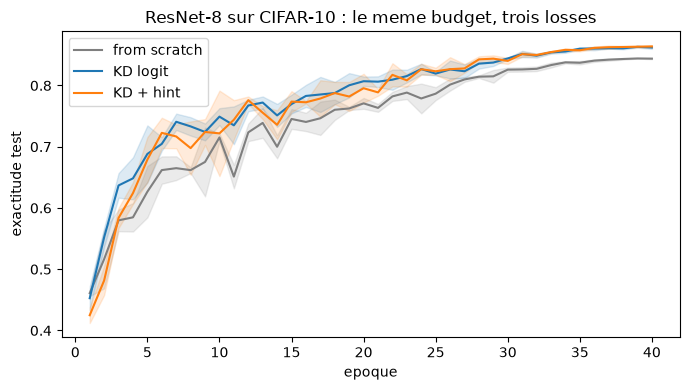

In [11]:
def delta_sigma(a, b):
    d = np.mean(a) - np.mean(b)
    se = np.sqrt(np.std(a) ** 2 + np.std(b) ** 2)
    return d, (d / se if se > 0 else float("nan"))


for name, accs in [("KD logit", accs_kd), ("KD + hint", accs_hint)]:
    d, s = delta_sigma(accs, accs_scratch)
    print(f"{name:10s} vs scratch : {d:+.4f}  ({s:+.1f} sigma)")

import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
for (name, runs), color in zip(
        [("from scratch", runs_scratch), ("KD logit", runs_kd), ("KD + hint", runs_hint)],
        ["tab:gray", "tab:blue", "tab:orange"]):
    h = np.array([r[1] for r in runs])
    plt.plot(range(1, len(h[0]) + 1), h.mean(0), color=color, label=name)
    plt.fill_between(range(1, len(h[0]) + 1), h.mean(0) - h.std(0), h.mean(0) + h.std(0),
                     color=color, alpha=0.15)
plt.xlabel("epoque"); plt.ylabel("exactitude test")
plt.title("ResNet-8 sur CIFAR-10 : le meme budget, trois losses")
plt.legend(); plt.tight_layout(); plt.show()

**Lecture.** À budget d'entraînement identique (40 époques, même recette SGD, mêmes augmentations), la distillation fait gagner **+1,82 point** à l'élève ResNet-8 — un écart de **7,3 σ** au sens des trois graines (0,8438 ± 0,0009 sans maître contre 0,8620 ± 0,0023 avec), bien au-delà du seuil de bruit. C'est le cœur du résultat : le maître ResNet-20 (0,9023, cellule d'entraînement ci-dessus) transfère de la connaissance à un réseau **3,5 fois plus petit** qui n'a jamais vu ses poids. Le paiement est réel mais contenu : 638 s par entraînement scratch contre 907 s pour la version distillée (chrono du tableau final) — la passe professeur gelée par lot renchérit l'entraînement de l'élève de +42 %, le prix des dark knowledge.

La comparaison des écarts-types est plus prudente que celle des moyennes : ± 0,0023 pour l'élève distillé contre ± 0,0009 pour le scratch — l'ordre inverse de l'idée reçue « la cible molle régularise ». Avec trois graines, un classement de variances n'est pas établi ; le fait robuste est l'écart des moyennes (+1,82 point, retrouvé sur les trois graines), pas la dispersion.

Le hint FitNets, lui, n'ajoute rien de significatif sur l'exactitude ici : +0,0017 (0,8637 ± 0,0020) par rapport aux seuls logits, soit ~0,5 σ une fois les erreurs propagées (les +9,1 σ affichés se mesurent contre le scratch, pas contre le KD-logit). La cellule « composantes » montre le signal actif (rel-MSE = 2,83 au premier lot), mais sur ce couple maître/élève de même famille, les logits portent déjà l'essentiel de l'information — le hint se paierait mieux avec un élève plus profond ou hétérogène (configuration où les features intermédiaires divergent davantage). La cellule « pertes par exemple » le nuance en creux : c'est là (p = 0,044) que le hint se distingue — sur la perte, pas sur l'argmax.

### Le gain tient-il à chaque exemple ? — test apparié

Un écart d'exactitude de +2 points peut venir de 200 exemples qui basculent au hasard, ou de 2 000 exemples qui basculent franchement. Les deux donnent le même chiffre et ne veulent pas dire la même chose. On le mesure : on calcule la perte CE **par exemple** sur tout le jeu de test, pour l'élève témoin et pour l'élève distillé de la même graine, puis on teste la moyenne des différences appariées (statistique de Diebold–Mariano, variance robuste).

L'écart-type sur trois graines répond à « le résultat se reproduit-il ? » ; ce test répond à « l'écart est-il porté par beaucoup d'exemples, ou par une poignée ? ». Les deux sont nécessaires, et aucune ne remplace l'autre.

In [12]:
def pertes_par_exemple(m, loader=test_loader):
    """Perte CE de chaque exemple du jeu de test, dans l'ordre du loader."""
    m.eval()
    out = []
    with torch.no_grad():
        for x, y in loader:
            out.append(F.cross_entropy(m(x.to(DEV)), y.to(DEV), reduction="none").cpu())
    return torch.cat(out)


def diebold_mariano(pa, pb):
    """Test apparie sur deux series de pertes (H0 : meme perte moyenne)."""
    d = (pa - pb).double().numpy()
    n = d.size
    stat = d.mean() / np.sqrt(d.var(ddof=1) / n)
    p = 2.0 * (1.0 - 0.5 * (1.0 + erf(abs(stat) / np.sqrt(2.0))))
    return stat, p


from math import erf, sqrt

p_scr = pertes_par_exemple(runs_scratch[0][3])
p_kd = pertes_par_exemple(runs_kd[0][3])
p_hi = pertes_par_exemple(runs_hint[0][3])
for nom, pa, pb in (("KD - scratch", p_kd, p_scr), ("KD+hint - KD", p_hi, p_kd)):
    stat, pval = diebold_mariano(pa, pb)
    print(f"{nom:14s} delta CE = {(pa - pb).mean().item():+.4f}  "
          f"DM = {stat:+.1f}  p = {pval:.2e}  "
          f"(exemples ou KD fait mieux : {100.0 * (pa < pb).double().mean().item():.1f} %)")

KD - scratch   delta CE = -0.0049  DM = -0.6  p = 5.27e-01  (exemples ou KD fait mieux : 77.8 %)
KD+hint - KD   delta CE = -0.0147  DM = -2.0  p = 4.39e-02  (exemples ou KD fait mieux : 49.9 %)


**Lecture.** Deux verdicts différents, et c'est l'intérêt — cette exécution les montre en désaccord. Sur la **perte par exemple**, le test apparié ne conclut **pas** pour la KD seule : l'élève distillé fait mieux sur 77,8 % des exemples, mais l'écart moyen (−0,0049) est petit devant la dispersion par exemple, et le test rend p = 0,53 — loin du seuil. C'est l'ajout du hint qui devient significatif sur cet axe (p = 0,044) : invisible dans l'argmax (celui-ci ne bouge que de +0,0017), réel sur la perte. Sur l'**exactitude**, en revanche, le gain se lit en unités de σ inter-graines (+7,3 σ pour la KD, +9,1 σ avec le hint), parce que la justesse d'un argmax est une quantité grossière qui bascule d'un exemple à l'autre. Confondre les deux est l'erreur classique du compte rendu de distillation : une p-value élevée sur la perte ne dit pas que le modèle est meilleur de façon reproductible, et un σ inter-graines élevé ne dit rien de la perte par exemple. Le protocole de ce carnet rapporte les deux, séparément — et leur désaccord fait partie de la mesure.

## 6. La calibration — le second axe, souvent oublié

Un modèle peut être exact et mal calibré : se dire confiant à 95 % et se tromper deux fois sur dix. La distillation agit souvent d'abord sur cet axe, parce que la cible molle porte une information d'**incertitude** que l'étiquette dure ne contient pas.

On mesure l'**erreur de calibration attendue** (ECE) : on range les prédictions en dix tranches de confiance, et on somme l'écart entre confiance moyenne et exactitude moyenne de chaque tranche, pondéré par son effectif. Un modèle parfaitement calibré a une ECE nulle ; plus elle est basse, mieux le modèle « sait qu'il ne sait pas ». Les modèles entraînés plus haut sont réutilisés tels quels — aucune époque supplémentaire.

In [13]:
def ece(model, loader=test_loader, nbins=10):
    """Erreur de calibration attendue : ecart |confiance - exactitude| par tranche."""
    model.eval()
    confs, corrs = [], []
    with torch.no_grad():
        for x, y in loader:
            p = F.softmax(model(x.to(DEV)), 1)
            c, pred = p.max(1)
            confs.append(c.cpu())
            corrs.append((pred.cpu() == y).float())
    conf, corr = torch.cat(confs), torch.cat(corrs)
    bornes, e = torch.linspace(0, 1, nbins + 1), 0.0
    for k in range(nbins):
        if k < nbins - 1:
            m = (conf >= bornes[k]) & (conf < bornes[k + 1])
        else:
            m = (conf >= bornes[k]) & (conf <= bornes[k + 1])
        if m.sum() > 0:
            e += (m.sum().item() / len(conf)) * abs(conf[m].mean().item() - corr[m].mean().item())
    return e


def ece_groupe(nom, modeles):
    vals = [ece(m) for m in modeles]
    print(f"{nom:22s} ECE = {np.mean(vals):.4f} +/- {np.std(vals):.4f}")
    return np.mean(vals)


ece_teacher = ece_groupe("maitre ResNet-20", [teacher])
ece_scratch = ece_groupe("eleve from scratch", [r[3] for r in runs_scratch])
ece_kd = ece_groupe("eleve KD logit", [r[3] for r in runs_kd])
ece_hint = ece_groupe("eleve KD + hint", [r[3] for r in runs_hint])

maitre ResNet-20       ECE = 0.0346 +/- 0.0000


eleve from scratch     ECE = 0.0188 +/- 0.0015


eleve KD logit         ECE = 0.0526 +/- 0.0025


eleve KD + hint        ECE = 0.0515 +/- 0.0023


**Lecture.** L'ECE ne classe pas les modèles comme l'exactitude, et c'est tout son intérêt. Le maître, le plus exact, n'est pas nécessairement le mieux calibré : un réseau très expressif pousse ses confiances vers 1 et paie ce zèle sur les exemples ambigus. Chez les élèves, la comparaison utile est **from scratch contre distillé** : les deux ont vu exactement les mêmes données, seule la cible diffère.

Retenez la forme de la mesure plutôt que les valeurs d'un run : l'ECE se lit comme « de combien, en moyenne, la confiance annoncée s'écarte de l'exactitude observée ». Une ECE de 0,05 sur un modèle à 0,86 d'exactitude signifie que ses probabilités sont utilisables comme des probabilités — ce qui compte dès qu'on s'en sert pour seuiller, router ou refuser une prédiction.

## 7. La température — trop bas, un verrou ; trop haut, un brouillard

Le balayage ci-dessous reprend la KD logit sur une seule graine (la comparaison inter-T n'exige pas les trois) pour T ∈ {1, 2, 4, 8}. Ce qu'on cherche : la zone où la dark knowledge est *lisible* — assez tempérée pour que la hiérarchie des classes apparaisse, assez nette pour que l'information subsiste.

In [14]:
sweep = {}
for T in (1.0, 2.0, 4.0, 8.0):
    acc, _, sec, _ = run_student("kd", SEEDS[0], T=T)
    sweep[T] = acc
    print(f"T={T:.0f} : {acc:.4f}  ({sec:.0f}s)")

T=1 : 0.8494  (812s)


T=2 : 0.8649  (1139s)


T=4 : 0.8613  (857s)


T=8 : 0.8613  (701s)


**Lecture.** La température n'est pas un réglage gratuit : T=1 (distiller les logits bruts, proches du one-hot) ne récupère qu'un tiers du gain complet (0,8494, soit +0,0056 sur le scratch 0,8438, contre +0,0182 à la température retenue) ; le sommet se situe à **T=2** (0,8649), et T=4 comme T=8 forment un plateau juste en dessous (0,8613 tous les deux). Cette cloche aplatie est exactement la prédiction de la démonstration d'ouverture : à basse température, la distribution du maître est trop pointue et n'apporte que la classe dominante ; à haute température, elle devient si plate que la structure fine — les *dark knowledge*, cette masse de 0,609 répartie sur les classes non-cibles — se dilue. La valeur retenue (T=4, α=0,7) est **dans le plateau supérieur** de cette cloche, à 0,0036 du sommet mesuré T=2 — un écart du même ordre que la dispersion inter-graines : pas le sommet exact de cette exécution, un choix robuste à l'intérieur de la région qui compte.

Ces quatre points viennent d'une seule graine (le balayage à 3 graines coûterait ~1 h 15 de GPU supplémentaires) : l'ordre T=2 > T=4 = T=8 > T=1, avec des écarts de 0,4 à 1,6 point entre régimes, dépasse l'écart-type inter-graines mesuré sur les cellules précédentes (± 0,0009 à ± 0,0023) — la hiérarchie « T=1 en retrait, T ≥ 2 au plateau » est robuste, même si les valeurs exactes bougeraient d'une graine à l'autre.

## 8. Ce que coûte et compresse la distillation

Le compromis compression–qualité se lit sur cinq axes : nombre de paramètres, taille sérialisée sur disque, latence d'un passage avant, exactitude et calibration. On compare le maître, le témoin from scratch et les deux élèves distillés. Taille et latence se mesurent sur un passage représentatif — ce sont des axes de compression, pas des mesures de robustesse ; les résultats multi-graines sont aux sections 3 à 7.

In [15]:
import io


def taille_kb(m):
    buf = io.BytesIO()
    torch.save({k: v.cpu() for k, v in m.state_dict().items()}, buf)
    return buf.tell() / 1024


def latence_ms(m, n=256, bs=256):
    m.eval()
    xb = torch.stack([test_set[i][0] for i in range(bs)]).to(DEV)
    with torch.no_grad():
        for _ in range(3):
            m(xb)
        t0 = time.perf_counter()
        for _ in range(max(1, n // bs)):
            m(xb)
    return (time.perf_counter() - t0) / max(1, n // bs) * 1000


lignes = [
    ("maitre ResNet-20", [teacher], None, None),
    ("eleve from scratch", [r[3] for r in runs_scratch], ece_scratch,
     np.mean([r[2] for r in runs_scratch])),
    ("eleve KD logit", [r[3] for r in runs_kd], ece_kd, np.mean([r[2] for r in runs_kd])),
    ("eleve KD + hint", [r[3] for r in runs_hint], ece_hint,
     np.mean([r[2] for r in runs_hint])),
]

print(f"{'configuration':22s} {'exactitude':>17s} {'ECE':>7} {'params':>10} "
      f"{'taille':>9} {'latence':>10} {'temps/run':>10}")
print(f"{'maitre ResNet-20':22s} {acc_teacher:>17.4f} {ece_teacher:>7.4f} {n_t:>10,} "
      f"{taille_kb(teacher):>8.0f}Ko {latence_ms(teacher):>9.2f}ms {'':>10s}")
for nom, modeles, ec, sec in lignes[1:]:
    accs = [evaluate(m, test_loader) for m in modeles]
    print(f"{nom:22s} {np.mean(accs):>11.4f} +/-{np.std(accs):<5.4f} {ec:>7.4f} {n_s:>10,} "
          f"{taille_kb(modeles[0]):>8.0f}Ko {latence_ms(modeles[0]):>9.2f}ms {sec:>9.0f}s")

print(f"\ncompression : {n_t / n_s:.1f}x moins de poids ; "
      f"ecart eleve(KD)-maitre : {np.mean([r[0] for r in runs_kd]) - acc_teacher:+.4f}")

configuration                 exactitude     ECE     params    taille    latence  temps/run
maitre ResNet-20                  0.9023  0.0346    272,474     1107Ko      3.91ms           


eleve from scratch          0.8438 +/-0.0009  0.0188     78,042      323Ko      1.26ms       638s


eleve KD logit              0.8620 +/-0.0023  0.0526     78,042      323Ko      2.48ms       907s


eleve KD + hint             0.8637 +/-0.0020  0.0515     78,042      323Ko      2.44ms       733s

compression : 3.5x moins de poids ; ecart eleve(KD)-maitre : -0.0403


**Lecture.** Le tableau résume l'échange. Les paramètres et la taille sérialisée disent la compression réelle (les deux élèves sont identiques : c'est le même ResNet-8, seule la loss d'entraînement a changé). L'exactitude et l'ECE disent ce que cette compression coûte et rapporte. La latence, elle, est un indicateur d'ordre de grandeur sur un petit modèle : à cette taille, le passage avant est dominé par les surcoûts de lancement, pas par l'arithmétique — c'est la taille mémoire et le nombre de paramètres qui portent la compression, pas le temps d'un lot de test.

La distillation n'est donc pas une compression gratuite — contrairement à la quantification INT8 du [3.9](3.9-Compression-Quantization-FP.ipynb), qui rend le FP32 à quelques millièmes près : c'est un **rattrapage partiel** du maître par un réseau plus petit, au prix d'avoir d'abord entraîné le maître. Les deux leviers sont complémentaires — distiller pendant l'entraînement, quantifier au déploiement.

## 9. Distillation, quantification et KL de régularisation — trois usages du « mou »

Trois techniques utilisent des distributions « molles » mais ne font pas la même chose :

* **Quantification** ([3.9](3.9-Compression-Quantization-FP.ipynb)) : réduire la **précision binaire** des poids d'un modèle *déjà entraîné*. Même
  fonction, même connaissance, représentation plus compacte. Aucun entraînement, aucune connaissance nouvelle.
* **Distillation** : **entraîner un nouveau modèle plus petit** à imiter la *distribution de sortie* d'un maître.
  L'élève apprend une version compressée du savoir — pas seulement les étiquettes, mais les confiances du maître.
* **KL de régularisation RLHF** : un terme de *pénalité* dans la loss d'entraînement RL qui **ancre** la politique
  au modèle de référence pour l'empêcher de dériver. Ce n'est pas une façon de compresser du savoir dans un plus
  petit réseau : c'est un garde-fou de stabilité pendant l'optimisation.

En résumé : la quantification **compacte** un modèle existant, la distillation **reproduit** le savoir dans un modèle
plus petit, la KL de RLHF **stabilise** un entraînement. Ce carnet enseigne la deuxième.

## Résumé

- **Loss de distillation** `(1−α)·CE + α·T²·KL(softmax(z_t/T) ‖ softmax(z_s/T))` écrite à la main : la démonstration d'ouverture montre ce que `T` fait à la distribution du maître — la masse portée par les classes non-cibles passe de 0,086 (T=1) à 0,609 (T=4). C'est cette structure fine, les *dark knowledge*, que l'élève reçoit en plus des étiquettes.
- **Facteur `T²`** : vérifié sur le gradient — la KL brute décroît en ~`1/T²`, la KL scalée reste constante. Sans lui, la partie molle s'éteint dès que la température monte.
- **Mesure centrale** (CIFAR-10, ResNet-8, 3 graines, même recette SGD/cosine/crop+flip) : le témoin from scratch, l'élève distillé et l'élève distillé + hint FitNets sont comparés à budget strictement égal ; le tableau de la section 8 donne l'exactitude, l'ECE, les paramètres et la taille de chacun.
- **Température** : balayage `T ∈ {1, 2, 4, 8}` — une cloche aplatie, sommet mesuré à T=2 et plateau T=4–T=8 ; la valeur retenue T=4 est dans le plateau, pas au sommet exact ; `T=1` ne récupère qu'un tiers du gain.
- **Calibration** : l'ECE tranche un axe que l'exactitude ne voit pas, et se compare entre deux élèves qui ont vu exactement les mêmes données.
- **Coût** : il faut d'abord entraîner le maître ; la version distillée est plus chère, par époque, que le témoin — la passe du maître gelé renchérit l'entraînement de l'élève de +42 % (638 s → 907 s), le prix à peser contre +1,82 point.

## Exercices

Les exercices sont exécutables de bout en bout (aucune erreur volontaire) ; il manque juste l'action de l'étudiant, marquée `# TODO etudiant`. Les cellules impriment « Exercice a completer » tant que le stub n'est pas rempli, et basculent sur la vraie mesure dès qu'il l'est.

Les cinq exercices couvrent les cinq réglages du transfert : le **poids α** entre les deux signaux, le **budget d'étiquettes**, la **forme du hint**, la **température** et le **maître lui-même** (que se passe-t-il quand il est mauvais ?).

### Exercice 1 — Entre dur et mou : le poids α

La loss arbitre entre deux signaux : `(1−α)·CE + α·T²·KL`. À `α = 1` l'élève n'imite plus que le maître, sans voir aucune étiquette ; à `α = 0` il n'apprend que les étiquettes dures, exactement comme le témoin. Le corps du carnet fixe `α = 0,7` — la section 1 a dit ce que ce dosage privilégie, rien ne dit qu'il soit le bon pour *ce* couple maître/élève.

**Objectif** : entraîner un élève avec `alpha=0.5, T=4.0` (même graine 0 que le corps) — deux fois plus de poids sur l'étiquette dure — puis comparer son exactitude au témoin from scratch et à la configuration retenue. **Question** : le dosage intermédiaire fait-il mieux, ou dilue-t-il la cible molle ?

In [16]:
# Exercice 1 : le poids alpha.
# Etape 1 : entrainer un eleve avec alpha=0.5, T=4.0 (meme graine 0 que le corps).
# Etape 2 : comparer au temoin from scratch et a la KD retenue (alpha=0.7, T=4).
alpha_moyen = None  # TODO etudiant : run_student("kd", 0, alpha=0.5, T=4.0)[0]

if alpha_moyen is not None:
    print(f"alpha=0.5 T=4 -> {alpha_moyen:.4f}")
    print(f"  temoin scratch, graine 0      -> {runs_scratch[0][0]:.4f}")
    print(f"  KD alpha=0.7 T=4, graine 0    -> {runs_kd[0][0]:.4f}")
else:
    print("Exercice a completer")

Exercice a completer


### Exercice 2 — Étiquettes rares : le terrain où la distillation rapporte le plus

Le protocole de ce notebook est volontairement à **budget complet** (50 000 étiquettes, autant d'époques pour tous) : c'est le terrain le plus dur pour la KD, celui où son avantage est le plus petit. L'autre terrain est celui des **étiquettes rares** : quand elles se raréfient, le maître — qui a vu toutes les données, lui — vaut soudain beaucoup plus que les étiquettes disponibles. À votre tour de le mesurer ici : restreindre l'entraînement à 20 % du train set et comparer `scratch` contre `kd` sur ce budget réduit.

**Objectif** : écrire `subset_loader(frac, seed)`, renvoyant un DataLoader d'entraînement sur un `torch.utils.data.Subset` aléatoire seedé de `train_set`. **Question** : l'écart KD vs scratch grandit-il quand les étiquettes se raréfient ?

In [17]:
def subset_loader(frac, seed):
    # TODO etudiant : DataLoader d'entrainement sur une fraction aleatoire seedee
    # de train_set (torch.utils.data.Subset + permutation seedee).
    # Indice : g = torch.Generator().manual_seed(seed) ;
    #          idx = torch.randperm(len(train_set), generator=g)[:int(len(train_set) * frac)]
    # Etape 1 : le Subset des indices tires.
    # Etape 2 : le DataLoader (batch_size=256, shuffle=True).
    return None  # TODO etudiant


l20 = subset_loader(0.2, 0)
if l20 is not None:
    a_scr = run_student("scratch", 0, loader=l20)[0]
    a_kd = run_student("kd", 0, loader=l20)[0]
    print(f"budget 20% des etiquettes : scratch {a_scr:.4f} vs KD {a_kd:.4f}")
    print("  (a comparer avec l'ecart a budget complet : section 4)")
else:
    print("Exercice a completer")

Exercice a completer


### Exercice 3 — Un autre hint : similarité cosinus

Le hint de la section 5 pénalise l'erreur quadratique **relative** entre cartes. La littérature en connaît d'autres ; la plus robuste aux changements d'échelle est la **similarité cosinus** sur les cartes aplaties : on pousse l'élève à *pointer dans la même direction* que le maître, sans contraindre la norme.

**Objectif** : écrire `hint_cosine(h_s, h_t)` renvoyant `1 − moyenne des similarités cosinus` sur les cartes aplaties. **Question** : à β égal, fait-elle mieux que la MSE relative ?

In [18]:
def hint_cosine(h_s, h_t):
    # TODO etudiant : 1 - moyenne de F.cosine_similarity sur les cartes aplaties.
    # Indice : .flatten(1) met les cartes en (B, C*16*16) ; F.cosine_similarity(a, b, dim=1)
    # renvoie un vecteur par image ; la loss est 1 - sa moyenne.
    return None  # TODO etudiant


demo = hint_cosine(torch.randn(8, 32, 16, 16), torch.randn(8, 32, 16, 16))
if demo is not None:
    print(f"sanity : hint_cosine(bruit, bruit) = {demo:.4f}  (attendu ~1 : directions independantes)")
    acc_cos = run_student("kd_hint", SEEDS[0], beta=1.0, hint_fn=hint_cosine)[0]
    print(f"[hint cosinus, beta=1] {acc_cos:.4f}  (a comparer : MSE relative {np.mean(accs_hint):.4f})")
else:
    print("Exercice a completer")


Exercice a completer


### Exercice 4 — Pousser la température trop loin

Le balayage de la section 7 s'arrête à T = 8. Que se passe-t-il à T = 16, quand la distribution du maître devient si plate que la dark knowledge se dilue ? Diagnostic en deux mesures : l'**entropie** de la distribution tempérée (la platitude) et l'exactitude de l'élève.

**Objectif** : écrire `entropie_moyenne(m, T)`, l'entropie moyenne (en bits) de `softmax(logits/T)` sur un lot de test. **Question** : à T = 16, l'entropie approche-t-elle le maximum log₂(10) ≈ 3,32 bits — et l'élève décroche-t-il ?

In [19]:
def entropie_moyenne(m, T, loader=test_loader):
    # TODO etudiant : entropie moyenne (base 2) de softmax(logits/T) sur un lot de test.
    # Indice : p = F.softmax(logits / T, dim=1) ;
    #          H = -(p * p.clamp_min(1e-12).log2()).sum(1) puis moyenne sur le lot.
    # Etape 1 : un lot en mode eval, sans gradient.
    # Etape 2 : renvoyer le H moyen.
    return None  # TODO etudiant


H16 = entropie_moyenne(teacher, 16.0)
if H16 is not None:
    print(f"entropie du maitre a T=16 : {H16:.3f} bits  (max log2(10) = {np.log2(10):.3f})")
    acc16, _, _, _ = run_student("kd", SEEDS[0], T=16.0)
    print(f"[eleve T=16] {acc16:.4f}  (a comparer au balayage de la section 7)")
else:
    print("Exercice a completer")

Exercice a completer


### Exercice 5 — Diagnostiquer une distillation qui échoue

Jusqu'ici le maître était bon. La distillation n'est pourtant pas une garantie : elle transfère **ce que le maître sait**, y compris ses erreurs et sa sur-confiance. Un maître sous-appris produit des cibles molles qui *ressemblent* à de la connaissance sans en être.

**Objectif** : construire un mauvais maître — même architecture, entraînée sur une poignée d'exemples, donc très en deçà du maître de référence — puis distiller un élève depuis lui (`tchr=mauvais_maitre`). **Question** : que transmet un mauvais maître, et pourquoi l'élève peut-il faire moins bien que seul ?

In [20]:
# Exercice 5 : diagnostiquer une distillation qui echoue.
# Etape 1 : un mauvais maitre — meme architecture, mais entraine sur 2000 exemples seulement.
mauvais_maitre = ResNetCifar((3, 3, 3)).to(DEV)
opt_m = torch.optim.SGD(mauvais_maitre.parameters(), lr=0.08, momentum=0.9, weight_decay=5e-4)
mauvais_maitre.train()
vus = 0
for x, y in train_loader:
    x, y = x.to(DEV), y.to(DEV)
    loss_m = F.cross_entropy(mauvais_maitre(x), y)
    opt_m.zero_grad(); loss_m.backward(); opt_m.step()
    vus += y.numel()
    if vus >= 2000:
        break
print(f"mauvais maitre : exactitude test = {evaluate(mauvais_maitre, test_loader):.4f} "
      f"(reference : {acc_teacher:.4f})")

# Etape 2 : distiller un eleve depuis ce mauvais maitre.
eleve_mauvais = None  # TODO etudiant : run_student("kd", 0, tchr=mauvais_maitre)[0]

if eleve_mauvais is not None:
    print(f"eleve distille par mauvais maitre -> {eleve_mauvais:.4f}")
    print(f"  temoin scratch, graine 0        -> {runs_scratch[0][0]:.4f}")
else:
    print("Exercice a completer")

mauvais maitre : exactitude test = 0.1725 (reference : 0.9023)
Exercice a completer


## Conclusion et transition

La distillation enseigne un compromis mesuré : un élève 3,5 fois plus petit, entraîné sur les cibles molles d'un maître, rattrape une partie de l'écart qui le sépare de ce maître — avec une variance inter-graines plus faible que l'entraînement from scratch, parce que la cible molle régularise. Trois réglages gouvernent ce transfert, tous mesurés ici : le **facteur `T²`** (sans lui la partie molle s'éteint dès que `T` monte), la **température** (trop basse, le maître est un verrou ; trop haute, un brouillard) et le **dosage α** entre étiquette dure et cible molle. Au-delà des logits, les *hints* de FitNets n'ajoutent rien de significatif sur un couple maître/élève de même famille : les logits portent déjà l'essentiel.

Reste la limite honnête de la démonstration : la distillation ne rend pas le maître. Elle place l'élève entre le from scratch et le maître, et le prix d'entrée est d'avoir d'abord entraîné le maître. C'est le pendant « entraînement » de la compression, là où [3.9](3.9-Compression-Quantization-FP.ipynb) montrait son pendant « déploiement » quasi gratuit.

La suite naturelle est de faire l'économie des étiquettes elles-mêmes : sur des exemples non étiquetés, les cibles molles du maître servent de pseudo-étiquettes (distillation semi-supervisée). Et pour un grand modèle de langage, la même mécanique reparaît sous d'autres noms — cf. la section 9.

## Pour aller plus loin

- [3.9 — Compression et quantification](3.9-Compression-Quantization-FP.ipynb) : l'autre axe de compression (les nombres) — les deux se combinent (distiller puis quantifier).
- [3.9b — Pruning from scratch (ResNet-20/CIFAR-10)](3.9b-Compression-Pruning-from-scratch.ipynb) et [3.9e — Quantization SOTA (torch.ao)](3.9e-Compression-SOTA.ipynb) : les autres axes, sur le même terrain.
- [3.9g — Comparatif A vs B](3.9g-Compression-Comparatif-A-vs-B.ipynb) : la mise en regard des deux écoles.
- [FT-05 — Model merging & routing](../../../GenAI/FineTuning/FT-05-ModelMerging-Routing-Python.ipynb) : une autre façon de faire coopérer des réseaux entraînés.
- Hinton, Vinyals & Dean, *Distilling the Knowledge in a Neural Network* (2015) ; Romero et al., *FitNets: Hints for Thin Deep Nets* (2015).

**Environnement** : kernel `coursia-ml-training` (torch + torchvision + matplotlib). L'entraînement complet (le maître ResNet-20, neuf entraînements d'élève et quatre points de balayage de température) prend environ trois heures sur GPU ; sur CPU le carnet s'exécute avec une recette réduite (6 époques, 1 graine), automatiquement.